In [ ]:
%pip install puremacro


# Replicaciones de Referencia Empírica — Galí (1999) y Mertens-Ravn (2013)

**¿Cómo se transmiten las perturbaciones macroeconómicas fundamentales —choques de tecnología neutral e incrementos tributarios imprevistos— sobre el producto agregado, el empleo y las tasas de interés en las series de tiempo empíricas?**

Un objetivo central de la macroeconometría estructural es discernir entre paradigmas teóricos rivales a través de esquemas de identificación empírica rigurosos. Dos investigaciones representan hitos fundacionales en esta literatura:

1. **Jordi Galí (1999, *American Economic Review*)**:
   - *La Pregunta de Investigación*: ¿Provocan los choques tecnológicos positivos una expansión del empleo, como postulan los modelos de Ciclos Económicos Reales (RBC) de Kydland y Prescott (1982)? ¿O, por el contrario, las horas trabajadas se contraen en el impacto, como predicen los modelos Neokeynesianos con precios rígidos?
   - *La Estrategia de Identificación*: Aplica las restricciones de largo plazo de Blanchard y Quah (1989) en un modelo de Vectores Autorregresivos Estructurales (SVAR). La tecnología se identifica como el único choque estructural con efectos permanentes sobre el nivel de productividad laboral ($Y_t / N_t$).
   - *El Hallazgo Empírico*: En los datos de posguerra de Estados Unidos, las horas trabajadas sufren una contracción persistente tras una mejora tecnológica. Bajo rigidez de precios, la demanda agregada no se expande de inmediato, permitiendo a las empresas monopolísticas satisfacer la demanda con una menor cantidad de horas de trabajo ($N = Y / A$).

2. **Karel Mertens y Morten Ravn (2013, *American Economic Review*)**:
   - *La Pregunta de Investigación*: ¿Cuál es la magnitud empírica del multiplicador del gasto tributario y cómo reacciona la política monetaria ante una consolidación fiscal?
   - *La Estrategia de Identificación*: Emplea el método de Instrumentos Externos (Proxy SVAR / SVAR-IV) formalizado por Stock y Watson (2012) y Mertens y Ravn (2013). Utiliza los registros narrativos de modificaciones legislativas tributarias federales (Romer & Romer 2010) como instrumentos exógenos $z_t$ para identificar choques impositivos.
   - *El Hallazgo Empírico*: Un incremento impositivo imprevisto equivalente al 1% del PIB genera una contracción inmediata y estadísticamente significativa del PIB real, ante la cual la Reserva Federal suele responder reduciendo las tasas de interés.

En este tutorial interactivo replicamos íntegramente ambos estudios clásicos mediante `puremacro.datasets` y `puremacro.var.identify`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_cwd = Path.cwd()
sys.path.insert(0, str(_cwd if (_cwd / "_nbstyle.py").exists() else _cwd / "notebooks"))
import _nbstyle
_nbstyle.apply_style()

from puremacro.datasets import load_gali1999, load_narrative_tax_shocks, load_macro_quarterly
from puremacro.var.identify import bq, proxy

## 1. Replicación de Galí (1999, AER): Choques de Tecnología y Horas Trabajadas

Consideramos el vector bivariado $X_t = (\Delta x_t, \Delta n_t)^\top$, donde $\Delta x_t = \Delta \log(Y_t / N_t)$ es el crecimiento de la productividad del trabajo y $\Delta n_t$ es la primera diferencia de $n_t = \log(N_t)$, el logaritmo de las horas trabajadas per cápita. Es la propia *especificación en diferencias* de Galí: trata la productividad y las horas como I(1), con un VAR estacionario en primeras diferencias. El VAR en forma reducida es $X_t = \sum_{l=1}^p A_l X_{t-l} + u_t$ con matriz de covarianza de residuos $\Sigma_u = \mathbb{E}[u_t u_t^\top]$.

Invirtiendo el polinomio autorregresivo se obtiene la representación de media móvil de Wold:

$$ X_t = C(L) u_t = \sum_{k=0}^{\infty} C_k u_{t-k} $$

Los choques estructurales $\varepsilon_t = (\varepsilon_t^{tech}, \varepsilon_t^{non-tech})^\top$ se vinculan a las innovaciones reducidas por $u_t = B_0 \varepsilon_t$, con $\mathbb{E}[\varepsilon_t \varepsilon_t^\top] = I$. La matriz de impacto acumulado en el horizonte infinito $\bar{C} = C(1) B_0 = \left( I - \sum_{l=1}^p A_l \right)^{-1} B_0$ determina la respuesta de largo plazo.

La identificación de Blanchard-Quah restringe $\bar{C}$ a ser triangular inferior:

$$ \bar{C} = \begin{pmatrix} \bar{C}_{11} & 0 \\ \bar{C}_{21} & \bar{C}_{22} \end{pmatrix} \implies \bar{C} \bar{C}^\top = C(1) \Sigma_u C(1)^\top $$

Dado que $\bar{C}_{12} = 0$, los choques no tecnológicos tienen prohibido ejercer cualquier efecto permanente sobre el nivel de productividad laboral. El factor de Cholesky de $C(1) \Sigma_u C(1)^\top$ identifica de forma única la matriz estructural de impacto contemporáneo $B_0$.

Ambas variables entran en primeras diferencias, así que las respuestas de los *niveles* $x_t$ y $n_t$ son las sumas acumuladas de las respuestas estimadas de $\Delta x_t$ y $\Delta n_t$. Eso es lo que `bq` devuelve por defecto (`cumulate=True`). Si se introdujera el nivel $n_t$ manteniendo ese valor por defecto, se acumularía un nivel y la respuesta de las horas se convertiría en una suma acumulada espuria.

In [2]:
df_gali = load_gali1999()
df_gali["dhours"] = df_gali["hours"].diff()  # especificación en diferencias de Galí
gali_vars = df_gali[["dlprod", "dhours"]].dropna()
print("Vista Previa de los Datos de Galí (1999):")
print(gali_vars.head())
print(f"Muestra: {gali_vars.index[0]} a {gali_vars.index[-1]} ({len(gali_vars)} trimestres)")

# Estimación del VAR(4) con restricción BQ de largo plazo; ambas filas se acumulan a niveles
Z_gali = gali_vars.to_numpy(dtype=float)
bq_res = bq(Z_gali, p=4, horizon=20)
print("\n" + bq_res.summary())

prod, hours = bq_res.irf_point[:, 0, 0], bq_res.irf_point[:, 1, 0]
print(f"Productividad (nivel), choque tecnológico: h=0: {prod[0]:+.3f}  h=20: {prod[20]:+.3f}")
print(f"Horas per cápita (nivel), choque tecnológico: h=0: {hours[0]:+.3f}  h=20: {hours[20]:+.3f}")
print(f"Banda del 90% de las horas en h=0: [{bq_res.irf_lower[0, 1, 0]:+.3f}, {bq_res.irf_upper[0, 1, 0]:+.3f}]"
      f"  h=20: [{bq_res.irf_lower[20, 1, 0]:+.3f}, {bq_res.irf_upper[20, 1, 0]:+.3f}]")

Vista Previa de los Datos de Galí (1999):
          dlprod    dhours
date                      
1948Q3  0.108467  0.378658
1948Q4  0.437013 -1.084308
1949Q1  1.013754 -1.858863
1949Q2  1.024734 -1.905982
1949Q3  2.362002 -1.360349
Muestra: 1948Q3 a 2026Q1 (311 trimestres)



Blanchard-Quah SVAR result
  variables (n)     : 2
  horizon (H)       : 20
  CI level          : 0.90
  bootstrap draws   : 500 (dropped 0, 0.0%)

Productividad (nivel), choque tecnológico: h=0: +0.679  h=20: +0.812
Horas per cápita (nivel), choque tecnológico: h=0: -0.834  h=20: -0.402
Banda del 90% de las horas en h=0: [-1.335, -0.262]  h=20: [-1.002, +0.278]


### Respuestas al Impulso ante un Choque Tecnológico Positivo

Las funciones de respuesta al impulso con intervalos de confianza bootstrap al 90% revelan:
- **Panel Izquierdo (Nivel de Productividad)**: Un choque tecnológico positivo eleva el nivel de la productividad laboral ($x_t$) en torno a $+0.68\%$ en el impacto; el nivel se estabiliza cerca de $+0.81\%$ al cabo de cinco años, con una banda del 90% que se mantiene claramente por encima de cero.
- **Panel Derecho (Horas Trabajadas)**: En lugar de expandirse como predicen los modelos RBC de precios flexibles, las horas per cápita caen en torno a $-0.83\%$ en el impacto, y la banda del 90% excluye el cero en el impacto. La estimación puntual es negativa en todos los horizontes y se estabiliza cerca de $-0.40\%$, pero en $h=20$ la banda incluye el cero, de modo que la parte persistente de la caída se estima con poca precisión. El signo en el impacto es el resultado central de Galí: un comovimiento condicional negativo entre horas y productividad, que él interpreta como evidencia de rigideces nominales de precios.

Los datos incluidos cubren de 1948 a 2026, mucho más allá de la muestra 1948-1994 de Galí, y usan la versión actual de las series del BLS, así que las magnitudes no son las suyas; el resultado comparable es el signo en el impacto. Si las horas deben entrar en niveles o en diferencias es en sí una elección debatida (Christiano, Eichenbaum y Vigfusson 2003); `puremacro.examples.gali_1999_hours` compara ambas.

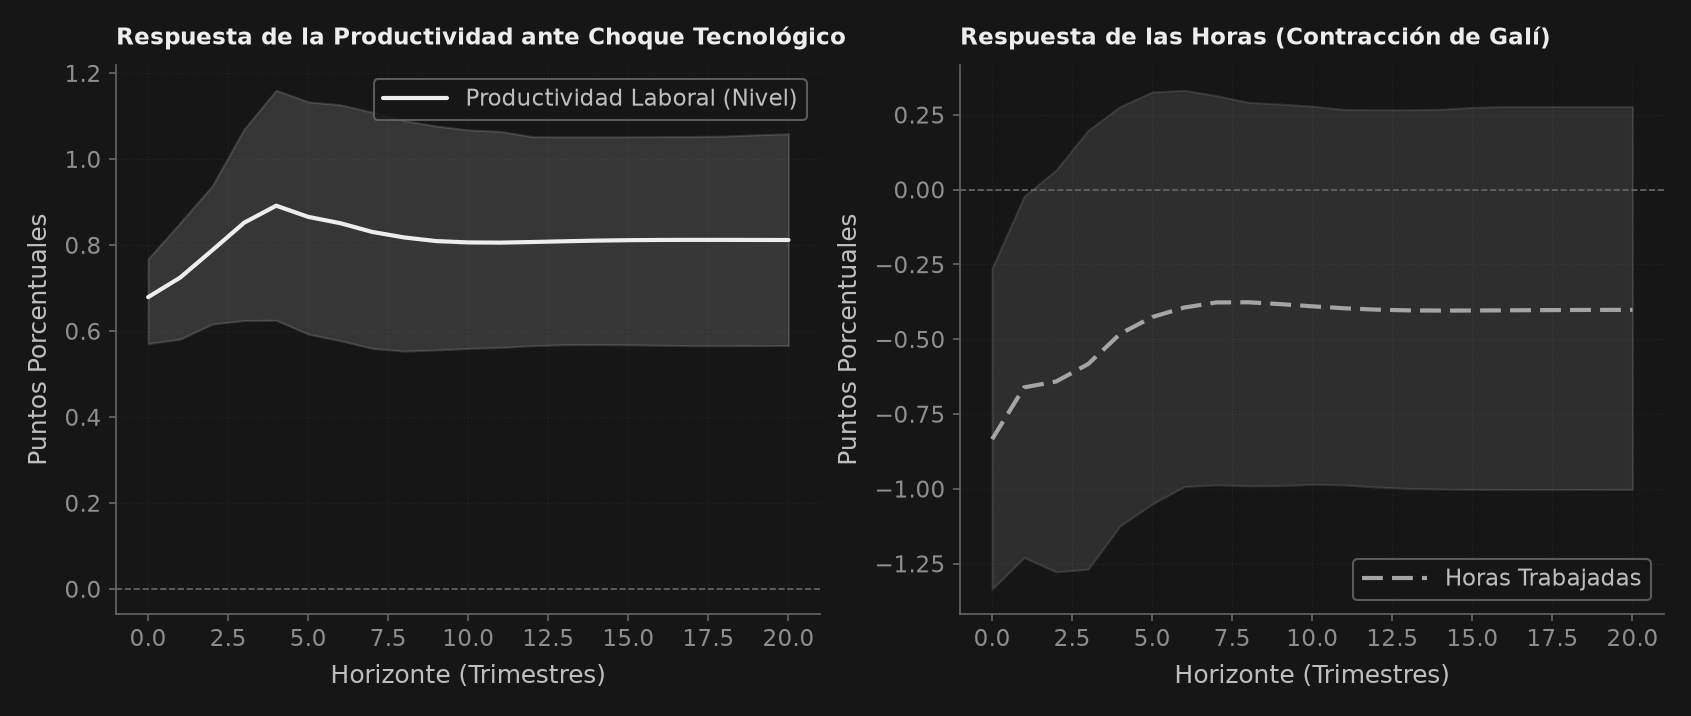

In [3]:
fig, (ax1, ax2) = _nbstyle.figura(1, 2, figsize=(11.0, 4.5))
h_gali = np.arange(len(bq_res.irf_point))

# Panel 1: Productividad Laboral (Nivel acumulado)
irf_prod = bq_res.irf_point[:, 0, 0]
irf_prod_lo = bq_res.irf_lower[:, 0, 0]
irf_prod_hi = bq_res.irf_upper[:, 0, 0]

ax1.plot(h_gali, irf_prod, **_nbstyle.S1, label="Productividad Laboral (Nivel)")
ax1.fill_between(h_gali, irf_prod_lo, irf_prod_hi, color=_nbstyle.TINTA, alpha=0.15)
ax1.axhline(0, color=_nbstyle.SPINE, lw=0.8, linestyle="--")
ax1.set_title("Respuesta de la Productividad ante Choque Tecnológico", fontsize=11, fontweight="bold")
ax1.set_xlabel("Horizonte (Trimestres)", color=_nbstyle.TEXTO)
ax1.set_ylabel("Puntos Porcentuales", color=_nbstyle.TEXTO)
ax1.legend(frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)
ax1.grid(True, linestyle=":", color=_nbstyle.REJILLA, alpha=0.8)

# Panel 2: Horas Trabajadas (Contracción en impacto)
irf_hours = bq_res.irf_point[:, 1, 0]
irf_hours_lo = bq_res.irf_lower[:, 1, 0]
irf_hours_hi = bq_res.irf_upper[:, 1, 0]

ax2.plot(h_gali, irf_hours, **_nbstyle.S2, label="Horas Trabajadas")
ax2.fill_between(h_gali, irf_hours_lo, irf_hours_hi, color=_nbstyle.TEXTO, alpha=0.15)
ax2.axhline(0, color=_nbstyle.SPINE, lw=0.8, linestyle="--")
ax2.set_title("Respuesta de las Horas (Contracción de Galí)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Horizonte (Trimestres)", color=_nbstyle.TEXTO)
ax2.set_ylabel("Puntos Porcentuales", color=_nbstyle.TEXTO)
ax2.legend(frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)
ax2.grid(True, linestyle=":", color=_nbstyle.REJILLA, alpha=0.8)

## 2. Replicación de Mertens y Ravn (2013, AER): Multiplicadores Tributarios Narrativos

Sea $Y_t = (y_t, r_t)^\top$ el sistema macroeconómico bivariado conformado por el logaritmo del PIB real $y_t$ y la tasa de fondos federales $r_t$. Los residuos de la forma reducida se relacionan con los choques estructurales $\varepsilon_t = (\varepsilon_t^{tax}, \varepsilon_t^{other})^\top$ mediante:

$$ u_t = b_1 \varepsilon_t^{tax} + b_2 \varepsilon_t^{other} $$

Mertens y Ravn (2013) utilizan la serie narrativa de cambios tributarios $m_t$ (estimaciones oficiales de recaudación proyectada ante reformas no motivadas por el ciclo económico corriente) como un instrumento externo que cumple:

$$ \mathbb{E}[m_t \varepsilon_t^{tax}] = \phi \neq 0 \quad (\text{Relevancia}), \qquad \mathbb{E}[m_t \varepsilon_t^{other}] = 0 \quad (\text{Exogeneidad}) $$

La covarianza entre los residuos del VAR y el instrumento determina:

$$ \mathbb{E}[u_t m_t] = b_1 \mathbb{E}[\varepsilon_t^{tax} m_t] = b_1 \phi \implies \frac{b_{1, i}}{b_{1, 1}} = \frac{\text{Cov}(u_{i, t}, m_t)}{\text{Cov}(u_{1, t}, m_t)} $$

El vector de impacto contemporáneo se identifica a través de Mínimos Cuadrados en Dos Etapas (MC2E) sin imponer restricciones de signos ni ordenamientos de Cholesky.

In [4]:
df_macro_q = load_macro_quarterly()
df_tax = load_narrative_tax_shocks()

common_idx = [idx for idx in df_macro_q.index if idx in df_tax.index]
sub_macro = df_macro_q.loc[common_idx]
sub_tax = df_tax.loc[common_idx]

gdp_log = np.log(sub_macro["real_gdp"].to_numpy(dtype=float)) * 100.0
ffr = sub_macro["fed_funds"].to_numpy(dtype=float)
Z_tax = np.column_stack([gdp_log, ffr])
m_instrument = sub_tax["unanticipated"].to_numpy(dtype=float)

proxy_res = proxy(Z_tax, p=4, horizon=16, instrument_series=m_instrument, shock_target_idx=0)
print(proxy_res.summary())

gdp_tax = proxy_res.irf_point[:, 0, 0]
h_trough = int(np.argmin(gdp_tax))
print(f"PIB real (%), choque impositivo: h=0: {gdp_tax[0]:+.3f}  mínimo: {gdp_tax[h_trough]:+.3f} en h={h_trough}"
      f"  h=12: {gdp_tax[12]:+.3f}")
print(f"Extremo superior de la banda del 90% del PIB, máximo en h=0..16: {proxy_res.irf_upper[:, 0, 0].max():+.3f}")

ffr_tax = proxy_res.irf_point[:, 1, 0]
print(f"Tasa de fondos federales (pp), choque fiscal: h=0: {ffr_tax[0]:+.3f}"
      f"  banda del 90% [{proxy_res.irf_lower[0, 1, 0]:+.3f}, {proxy_res.irf_upper[0, 1, 0]:+.3f}];"
      f"  rango en h=1..12: {ffr_tax[1:13].min():+.3f} a {ffr_tax[1:13].max():+.3f};"
      f"  extremo superior más alto de la banda en h=1..12: {proxy_res.irf_upper[1:13, 1, 0].max():+.3f}")

ProxySVAR result
  shocks identified : 1 (column 0 of B)
  variables (n)     : 2
  horizon (H)       : 16
  bootstrap draws   : 500
  CI level          : 0.90
  first-stage F (OP): 6.79  [WEAK (use weak-IV-robust inference)]

PIB real (%), choque impositivo: h=0: -0.739  mínimo: -1.131 en h=3  h=12: -0.960
Extremo superior de la banda del 90% del PIB, máximo en h=0..16: -0.582
Tasa de fondos federales (pp), choque fiscal: h=0: +0.154  banda del 90% [+0.034, +0.293];  rango en h=1..12: -0.310 a -0.038;  extremo superior más alto de la banda en h=1..12: +0.168


### Respuestas al Impulso ante un Incremento Impositivo Imprevisto

Las respuestas dinámicas estimadas mediante Proxy SVAR demuestran:
- **Panel Izquierdo (Contracción del Producto)**: Un alza impositiva imprevista va seguida de una caída duradera del producto real: el PIB queda en torno a $-0.74\%$ por debajo de su nivel base en el impacto, alcanza un mínimo de alrededor de $-1.13\%$ en el trimestre 3 y sigue en torno a $-0.96\%$ por debajo tras 12 trimestres, con la banda del 90% por debajo de cero en todos los horizontes. El estadístico F de primera etapa de 6.79 señala un instrumento débil, de modo que estas bandas bootstrap no son robustas a instrumentos débiles y pueden exagerar la precisión. El cuaderno no calcula un multiplicador fiscal.
- **Panel Derecho (Reacción de la Política Monetaria)**: La tasa de fondos federales sube unos $+0.15$ pp en el impacto (banda del 90% $[+0.03, +0.29]$) y se vuelve negativa desde el trimestre siguiente, entre $-0.31$ y $-0.04$ pp hasta $h=12$. Después del impacto la banda incluye el cero (su extremo superior llega a $+0.17$), así que los datos no identifican con precisión una relajación; léase solo como indicio.

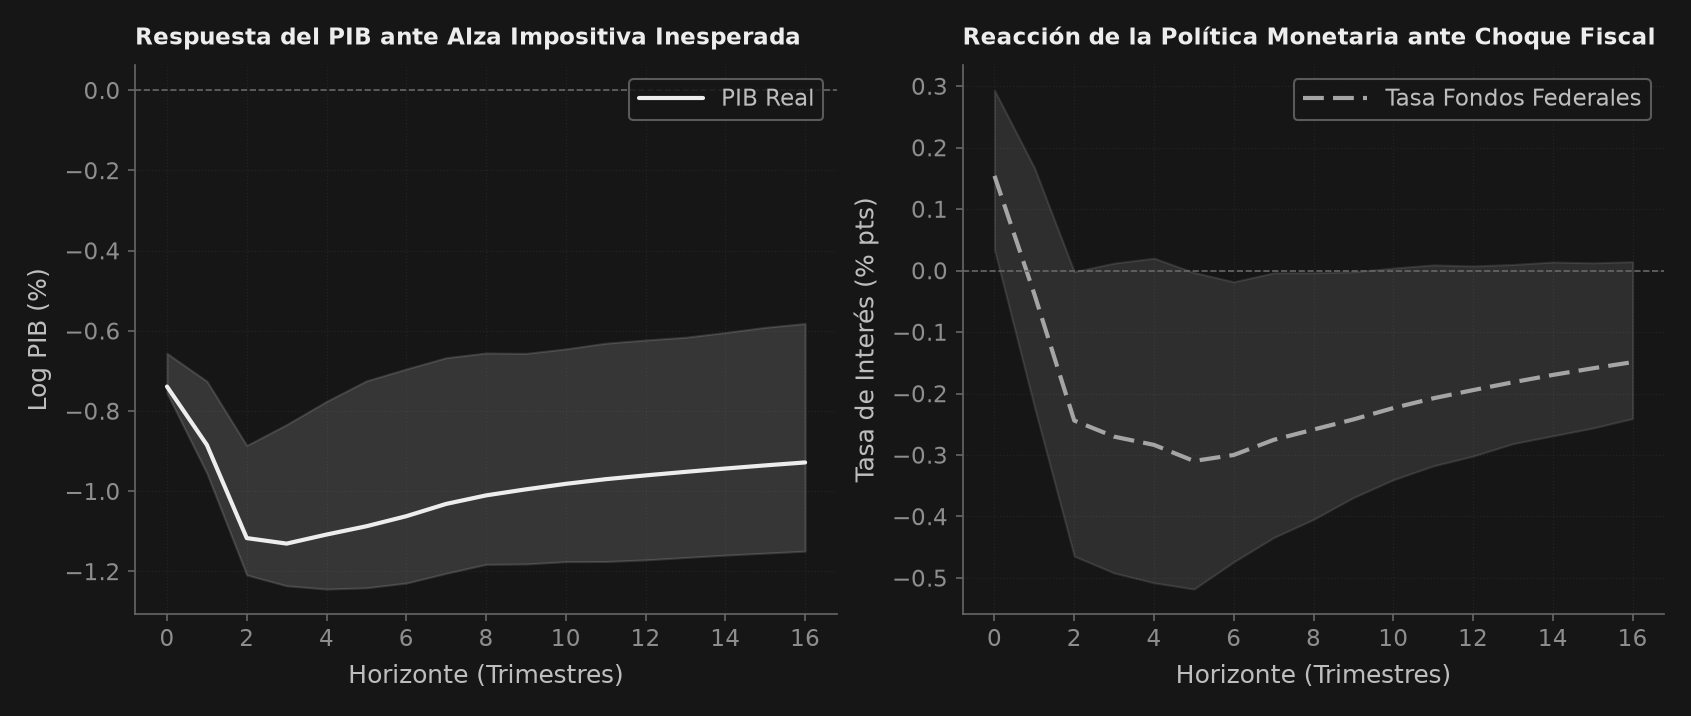

In [5]:
fig, (ax1, ax2) = _nbstyle.figura(1, 2, figsize=(11.0, 4.5))
h_tax = np.arange(len(proxy_res.irf_point))

irf_gdp = proxy_res.irf_point[:, 0, 0]
irf_gdp_lo = proxy_res.irf_lower[:, 0, 0]
irf_gdp_hi = proxy_res.irf_upper[:, 0, 0]

ax1.plot(h_tax, irf_gdp, **_nbstyle.S1, label="PIB Real")
ax1.fill_between(h_tax, irf_gdp_lo, irf_gdp_hi, color=_nbstyle.TINTA, alpha=0.15)
ax1.axhline(0, color=_nbstyle.SPINE, lw=0.8, linestyle="--")
ax1.set_title("Respuesta del PIB ante Alza Impositiva Inesperada", fontsize=11, fontweight="bold")
ax1.set_xlabel("Horizonte (Trimestres)", color=_nbstyle.TEXTO)
ax1.set_ylabel("Log PIB (%)", color=_nbstyle.TEXTO)
ax1.legend(frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)
ax1.grid(True, linestyle=":", color=_nbstyle.REJILLA, alpha=0.8)

irf_ffr = proxy_res.irf_point[:, 1, 0]
irf_ffr_lo = proxy_res.irf_lower[:, 1, 0]
irf_ffr_hi = proxy_res.irf_upper[:, 1, 0]

ax2.plot(h_tax, irf_ffr, **_nbstyle.S2, label="Tasa Fondos Federales")
ax2.fill_between(h_tax, irf_ffr_lo, irf_ffr_hi, color=_nbstyle.TEXTO, alpha=0.15)
ax2.axhline(0, color=_nbstyle.SPINE, lw=0.8, linestyle="--")
ax2.set_title("Reacción de la Política Monetaria ante Choque Fiscal", fontsize=11, fontweight="bold")
ax2.set_xlabel("Horizonte (Trimestres)", color=_nbstyle.TEXTO)
ax2.set_ylabel("Tasa de Interés (% pts)", color=_nbstyle.TEXTO)
ax2.legend(frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)
ax2.grid(True, linestyle=":", color=_nbstyle.REJILLA, alpha=0.8)